# TASK 01

In [5]:
# import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [7]:
# Load the California Housing dataset
df = pd.read_csv("california_housing.csv")

# Display the first five rows
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,3.7056,22.0,4.4502,1.1416,1773.0,3.0922,40.02,-122.25,1.7255
1,4.8575,36.0,5.7551,1.0897,199.0,3.6810,37.17,-118.79,2.9542
2,3.3045,9.0,8.6213,1.1102,754.0,3.5749,33.68,-115.29,2.1390
3,2.9988,16.0,6.0610,1.1367,310.0,4.7781,36.92,-122.10,1.9076
4,5.2304,6.0,5.2884,1.1086,1322.0,2.5858,41.01,-123.05,2.9634


In [8]:
# Features: all columns except the target
X = df.drop("MedHouseVal", axis=1)

# Target: median house value
y = df["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (5000, 8)
Target shape: (5000,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (4000, 8)
Testing features: (1000, 8)
Training target: (4000,)
Testing target: (1000,)


In [11]:
# Create the scaler
scaler = StandardScaler()

# Fit only on the training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform the test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Training feature means:")
print(X_train_scaled.mean(axis=0))

print("\nTraining feature standard deviations:")
print(X_train_scaled.std(axis=0))

Training feature means:
[-1.21680443e-16  4.44089210e-17  3.26849658e-16  6.05737682e-16
  3.55271368e-17 -2.95763414e-16 -1.00053299e-15 -3.33155725e-15]

Training feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1.]


# TASK-2

In [ ]:
#add a bias column
def add_bias(X):
    return np.c_[np.ones(len(X)), X]


# Add a bias column to training and testing data
Xtr = add_bias(X_train_scaled)
Xte = add_bias(X_test_scaled)

print("Training shape:", Xtr.shape)
print("Testing shape:", Xte.shape)

Training shape: (4000, 9)
Testing shape: (1000, 9)


In [39]:
# Closed-form solution using the normal equation
w_closed = np.linalg.inv(Xtr.T @ Xtr) @ Xtr.T @ y_train.values

print(w_closed)
print("\nBias (Intercept):", w_closed[0])

print("\nFeature Weights:")
for feature, weight in zip(X.columns, w_closed[1:]):
    print(f"{feature}: {weight}")

[ 2.20949088e+00  8.79915526e-01  1.69619588e-01  3.39813866e-02
  1.89607184e-03 -2.17350580e-03 -1.12160593e-01 -1.49141371e-01
 -1.70008580e-01]

Bias (Intercept): 2.209490875

Feature Weights:
MedInc: 0.8799155259271888
HouseAge: 0.16961958777365432
AveRooms: 0.033981386592376234
AveBedrms: 0.0018960718446026995
Population: -0.00217350580036782
AveOccup: -0.112160593221304
Latitude: -0.1491413705058259
Longitude: -0.17000858018055004


In [15]:
# Predict house values using the learned weights
pred_closed = Xte @ w_closed

print("First 10 Predictions:")
print(pred_closed[:10])

First 10 Predictions:
[3.68210434 1.2899429  1.4279813  1.32624661 2.77796395 2.46011531
 1.68590675 1.9673034  0.6576236  3.72322607]


In [16]:
# Mean Squared Error
mse_closed = np.mean((y_test.values - pred_closed) ** 2)

print("Test MSE:", mse_closed)

Test MSE: 0.16476915219656824


In [17]:
print("Number of weights:", len(w_closed))
print("Expected weights:", X.shape[1] + 1)


Number of weights: 9
Expected weights: 9


# Task-3

In [18]:
# Initialize all weights to zero
w_gd = np.zeros(Xtr.shape[1])

# Set the learning rate and number of iterations
lr = 0.1
n_iterations = 2000

# Store the loss at every iteration
loss_history = []

print("Initial weights:", w_gd)

Initial weights: [0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [19]:
# Convert target values into a NumPy array
y_train_array = y_train.values

# Number of training samples
n = len(y_train_array)

# Gradient Descent loop
for step in range(n_iterations):

    # Calculate predictions
    predictions = Xtr @ w_gd

    # Calculate errors
    errors = predictions - y_train_array

    # Calculate the gradient
    gradient = (2 / n) * (Xtr.T @ errors)

    # Update the weights
    w_gd = w_gd - lr * gradient

    # Calculate and store MSE
    loss = np.mean(errors ** 2)
    loss_history.append(loss)

print("Gradient Descent completed!")
print("Final training MSE:", loss_history[-1])

Gradient Descent completed!
Final training MSE: 0.1588040510046789


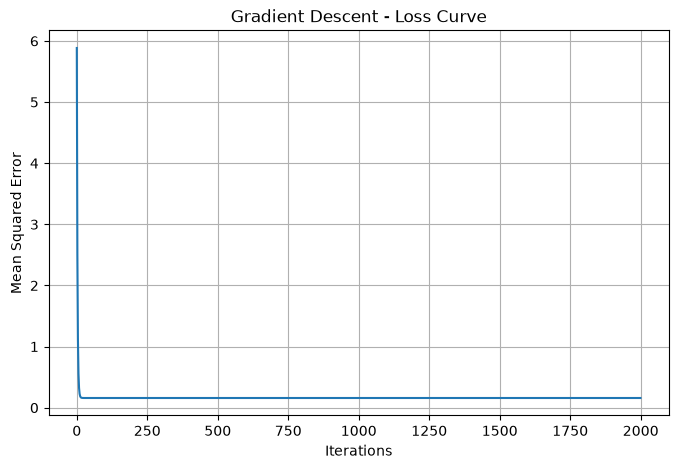

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent - Loss Curve")

plt.grid(True)
plt.show()

In [21]:
print("Bias (Intercept):", w_gd[0])

print("\nFeature Weights:")

for feature, weight in zip(X.columns, w_gd[1:]):
    print(f"{feature}: {weight}")

Bias (Intercept): 2.2094908749999984

Feature Weights:
MedInc: 0.8799155259271888
HouseAge: 0.1696195877736542
AveRooms: 0.03398138659237621
AveBedrms: 0.0018960718446027782
Population: -0.00217350580036782
AveOccup: -0.11216059322130398
Latitude: -0.14914137050582585
Longitude: -0.17000858018054993


In [22]:
# Compare the weights from both methods
comparison = pd.DataFrame({
    "Feature": ["Bias"] + list(X.columns),
    "Closed_Form": w_closed,
    "Gradient_Descent": w_gd
})

comparison["Difference"] = (
    comparison["Closed_Form"] - comparison["Gradient_Descent"]
)

comparison

,Feature,Closed_Form,Gradient_Descent,Difference
0,Bias,2.209491,2.209491,1.776357e-15
1,MedInc,0.879916,0.879916,0.000000e+00
2,HouseAge,0.169620,0.169620,1.110223e-16
3,AveRooms,0.033981,0.033981,2.081668e-17
4,AveBedrms,0.001896,0.001896,-7.871308e-17
5,Population,-0.002174,-0.002174,0.000000e+00
6,AveOccup,-0.112161,-0.112161,-2.775558e-17
7,Latitude,-0.149141,-0.149141,-5.551115e-17
8,Longitude,-0.170009,-0.170009,-1.110223e-16


In [23]:
print(
    "Do the weights match?",
    np.allclose(w_closed, w_gd, atol=1e-4)
)

Do the weights match? True


# Task-4

In [24]:
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train_scaled, y_train)

print("Model trained successfully!")

Model trained successfully!


In [25]:
print("Intercept (Bias):", model.intercept_)

print("\nFeature Coefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient}")

Intercept (Bias): 2.209490875

Feature Coefficients:
MedInc: 0.8799155259271901
HouseAge: 0.16961958777365424
AveRooms: 0.03398138659237621
AveBedrms: 0.0018960718446025958
Population: -0.002173505800367795
AveOccup: -0.11216059322130417
Latitude: -0.14914137050582638
Longitude: -0.1700085801805502


In [26]:
comparison = pd.DataFrame({
    "Feature": ["Bias"] + list(X.columns),
    "Closed_Form": w_closed,
    "Gradient_Descent": w_gd,
    "Sklearn": np.r_[model.intercept_, model.coef_]
})

comparison

,Feature,Closed_Form,Gradient_Descent,Sklearn
0,Bias,2.209491,2.209491,2.209491
1,MedInc,0.879916,0.879916,0.879916
2,HouseAge,0.169620,0.169620,0.169620
3,AveRooms,0.033981,0.033981,0.033981
4,AveBedrms,0.001896,0.001896,0.001896
5,Population,-0.002174,-0.002174,-0.002174
6,AveOccup,-0.112161,-0.112161,-0.112161
7,Latitude,-0.149141,-0.149141,-0.149141
8,Longitude,-0.170009,-0.170009,-0.170009


In [27]:
w_sklearn = np.r_[model.intercept_, model.coef_]

print(
    "Closed-form and Gradient Descent:",
    np.allclose(w_closed, w_gd, atol=1e-4)
)

print(
    "Closed-form and Sklearn:",
    np.allclose(w_closed, w_sklearn, atol=1e-8)
)

print(
    "Gradient Descent and Sklearn:",
    np.allclose(w_gd, w_sklearn, atol=1e-4)
)

Closed-form and Gradient Descent: True
Closed-form and Sklearn: True
Gradient Descent and Sklearn: True


In [28]:
pred_closed = Xte @ w_closed
pred_gd = Xte @ w_gd
pred_sklearn = model.predict(X_test_scaled)

print("Closed-form vs Sklearn:",
      np.allclose(pred_closed, pred_sklearn, atol=1e-8))

print("Gradient Descent vs Sklearn:",
      np.allclose(pred_gd, pred_sklearn, atol=1e-4))

Closed-form vs Sklearn: True
Gradient Descent vs Sklearn: True


# TASK-5

In [29]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [30]:
# Calculate MSE
mse = mean_squared_error(y_test, pred_sklearn)

# Calculate RMSE
rmse = np.sqrt(mse)

# Calculate MAE
mae = mean_absolute_error(y_test, pred_sklearn)

# Calculate R-squared
r2 = r2_score(y_test, pred_sklearn)

print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("Mean Absolute Error (MAE):", mae)
print("R-squared (R2):", r2)

Mean Squared Error (MSE): 0.16476915219656837
Root Mean Squared Error (RMSE): 0.4059176667706992
Mean Absolute Error (MAE): 0.3193210216517093
R-squared (R2): 0.8382895198507752


In [31]:
# Convert errors into dollars
rmse_dollars = rmse * 100000
mae_dollars = mae * 100000

print(f"RMSE in dollars: ${rmse_dollars:,.2f}")
print(f"MAE in dollars:  ${mae_dollars:,.2f}")

RMSE in dollars: $40,591.77
MAE in dollars:  $31,932.10


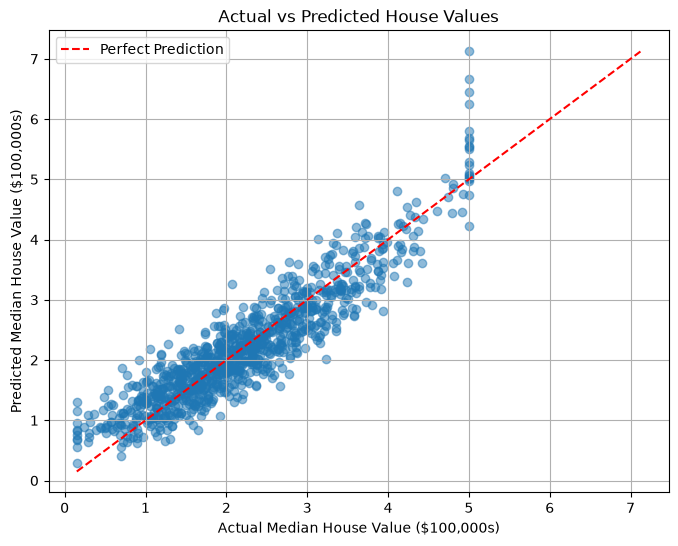

In [32]:
plt.figure(figsize=(8, 6))

# Scatter plot of actual and predicted values
plt.scatter(
    y_test,
    pred_sklearn,
    alpha=0.5
)

# Diagonal line for perfect predictions
lims = [
    min(y_test.min(), pred_sklearn.min()),
    max(y_test.max(), pred_sklearn.max())
]

plt.plot(lims, lims, "r--", label="Perfect Prediction")

plt.xlabel("Actual Median House Value ($100,000s)")
plt.ylabel("Predicted Median House Value ($100,000s)")
plt.title("Actual vs Predicted House Values")

plt.legend()
plt.grid(True)
plt.show()

# Task-6

In [33]:
coefs = pd.DataFrame({
    "Feature": X.columns,
    "Weight": model.coef_
})

# Sort by absolute coefficient size
coefs = coefs.reindex(
    coefs["Weight"].abs().sort_values(ascending=False).index
).reset_index(drop=True)

coefs

,Feature,Weight
0,MedInc,0.879916
1,Longitude,-0.170009
2,HouseAge,0.169620
3,Latitude,-0.149141
4,AveOccup,-0.112161
5,AveRooms,0.033981
6,Population,-0.002174
7,AveBedrms,0.001896


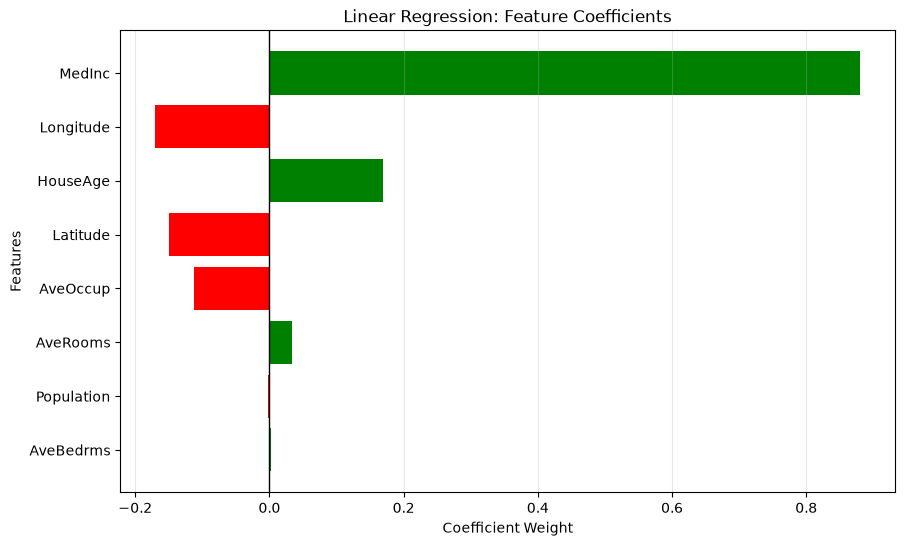

In [34]:
# Assign colors based on the sign of each coefficient
colors = [
    "green" if weight > 0 else "red"
    for weight in coefs["Weight"]
]

plt.figure(figsize=(10, 6))

plt.barh(
    coefs["Feature"],
    coefs["Weight"],
    color=colors
)

# Add a zero reference line
plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Coefficient Weight")
plt.ylabel("Features")
plt.title("Linear Regression: Feature Coefficients")

# Show the largest coefficient at the top
plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)
plt.show()

In [35]:
# Feature with the largest positive coefficient
strongest_positive = coefs.loc[coefs["Weight"].idxmax()]

# Feature with the largest negative coefficient
strongest_negative = coefs.loc[coefs["Weight"].idxmin()]

print("Strongest Positive Feature:")
print(strongest_positive)

print("\nStrongest Negative Feature:")
print(strongest_negative)

# Features with coefficients close to zero
near_zero = coefs[coefs["Weight"].abs() < 0.05]

print("\nFeatures with Near-Zero Coefficients:")
print(near_zero)

Strongest Positive Feature:
Feature      MedInc
Weight     0.879916
Name: 0, dtype: object

Strongest Negative Feature:
Feature    Longitude
Weight     -0.170009
Name: 1, dtype: object

Features with Near-Zero Coefficients:
      Feature    Weight
5    AveRooms  0.033981
6  Population -0.002174
7   AveBedrms  0.001896


Linear Regression is interpretable because its coefficients show how each feature is associated with the model's predictions, making it easier to explain and examine the model's behavior. This is valuable in areas such as loan approvals, healthcare, and hiring, where decisions may need clear explanations; more complex models can capture nonlinear patterns but may be harder to interpret.